<a href="https://colab.research.google.com/github/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/blob/main/Jobsheet%20Dataset%20PBL/JS14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JOBSHEET 14: CONVOLUTIONAL NEURAL NETWORK (CNN)
### Eksperimen Deep Learning Vision: Klasifikasi Citra Cat vs Dog, CIFAR-10 (Baseline & VGG-mini Modifikasi >80%), dan MNIST dengan Keras 3
**Mata Kuliah:** Pembelajaran Mesin — Semester 5 (Tahun Akademik 2025/2026)  
**Mahasiswa:** Wahyudi Satriawan Hamid  
**NIM / Kelas:** 244107020137 / TI-3H  
**Program Studi:** D-IV Teknik Informatika — Jurusan Teknologi Informasi — Politeknik Negeri Malang  

---

In [19]:
# =============================================================================
# SEL KODE 1: IMPORT LIBRARY, KONFIGURASI SEED, & VERIFIKASI GPU
# =============================================================================
import os
import sys
import pathlib
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow import keras
from keras import layers, models, callbacks

# 1. Konfigurasi Reproducibility (Random Seed)
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# 2. Verifikasi Lingkungan & Deteksi Akselerator GPU
print("=" * 70)
print("VERIFIKASI LINGKUNGAN DEEP LEARNING (KERAS 3 / TENSORFLOW)")
print("=" * 70)
print(f"Python Version     : {sys.version.split()[0]}")
print(f"TensorFlow Version : {tf.__version__}")
print(f"Keras Version      : {keras.__version__}")

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"Status Akselerator : [AKTIF] {len(gpus)} GPU terdeteksi -> {gpus[0].name}")
    try:
        # Memory growth untuk mencegah alokasi VRAM berlebihan
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("  - Konfigurasi Memory Growth: Berhasil diaktifkan")
    except Exception as e:
        print(f"  - Info Memory Growth: {e}")
else:
    print("Status Akselerator : [PERINGATAN] GPU TIDAK TERDETEKSI! Runtime berjalan pada CPU.")
    print("  -> Sangat disarankan mengaktifkan GPU T4 di Google Colab:")
    print("     Menu: Runtime -> Change runtime type -> Hardware accelerator: T4 GPU.")
print("=" * 70)


VERIFIKASI LINGKUNGAN DEEP LEARNING (KERAS 3 / TENSORFLOW)
Python Version     : 3.13.16
TensorFlow Version : 2.21.0
Keras Version      : 3.13.2
Status Akselerator : [AKTIF] 1 GPU terdeteksi -> /physical_device:GPU:0
  - Konfigurasi Memory Growth: Berhasil diaktifkan


---

# BAGIAN 1 — PRAKTIKUM 1: KLASIFIKASI CITRA BINER CAT VS DOG

## 1.1 Deskripsi Masalah & Dataset
Pada praktikum pertama ini, kita membangun model klasifikasi citra biner untuk membedakan antara citra **Kucing (*Cat*)** dan **Anjing (*Dog*)**.
Tantangan utama pada klasifikasi citra natural beresolusi variabel adalah tingginya variasi pose, sudut pencahayaan, latar belakang, dan skala objek.

## 1.2 Modernisasi Pipeline: Migrasi Penuh ke Keras 3 Modern
Modul praktikum asli menggunakan fungsi legasi `ImageDataGenerator` yang telah **usang (*deprecated*)** sejak TensorFlow 2.9 dan **dihapus/tidak didukung** pada Keras 3 modern. Pada notebook ini, seluruh pipeline dimigrasikan ke standar resmi Keras 3 / TensorFlow 2.16+:
1. **Auto-Download Portabel Tanpa Mount Google Drive:**  
   Menggunakan `tf.keras.utils.get_file` untuk mengunduh dataset resmi publik Google Storage (`cats_and_dogs_filtered.zip`, 2.000 citra latih dan 1.000 citra validasi). Pendekatan ini menjamin notebook dapat langsung dijalankan secara *one-click Run All* di Google Colab maupun mesin lokal tanpa memerlukan autentikasi login atau ketergantungan path Google Drive yang rentan putus.
2. **Deteksi Path Ekstraksi Dinamis (`pathlib.Path.rglob`):**  
   Perbedaan versi Keras 2 dan Keras 3 mengekstrak subdirektori dengan struktur path yang berbeda. Kode menggunakan pencarian rekursif dinamis `rglob('train')` dan `rglob('validation')`, menjamin portabilitas 100% kebal versi.
3. **Pemuatan Berbasis `tf.data.Dataset` via `image_dataset_from_directory`:**  
   Menghasilkan objek streaming data C++ yang hemat memori, mendukung paralelisasi multi-threaded, dan dilengkapi caching memory serta prefetching cerdas via `tf.data.AUTOTUNE`.
4. **Augmentasi Citra Terintegrasi Graf (`keras.layers`):**  
   Augmentasi (`RandomFlip`, `RandomRotation`, `RandomZoom`) didefinisikan sebagai layer Keras yang dieksekusi di GPU secara efisien selama tahap pelatihan dan otomatis non-aktif (*pass-through*) saat tahap evaluasi/inferensi.


In [20]:
# =============================================================================
# SEL KODE 2: AUTO-DOWNLOAD DATASET CAT VS DOG (MULTI-FALLBACK COLAB-READY)
# =============================================================================
import pathlib
import zipfile
from PIL import Image

base_dir = pathlib.Path("/content/cats_and_dogs_dataset")

def find_split_dirs(root):
    if not root.exists():
        return None, None
    t_dir = next(
        (p for p in root.rglob("train")
         if p.is_dir() and (p / "cats").is_dir() and (p / "dogs").is_dir()),
        None,
    )
    v_dir = next(
        (p for p in root.rglob("validation")
         if p.is_dir() and (p / "cats").is_dir() and (p / "dogs").is_dir()),
        None,
    )
    return t_dir, v_dir

def is_dataset_ready(t_dir, v_dir):
    if t_dir is None or v_dir is None:
        return False
    return (
        len(list((t_dir / "cats").glob("*.jpg"))) >= 1000
        and len(list((t_dir / "dogs").glob("*.jpg"))) >= 1000
        and len(list((v_dir / "cats").glob("*.jpg"))) >= 500
        and len(list((v_dir / "dogs").glob("*.jpg"))) >= 500
    )

train_dir, validation_dir = find_split_dirs(base_dir)

if not is_dataset_ready(train_dir, validation_dir):
    base_dir.mkdir(parents=True, exist_ok=True)
    downloaded = False

    # Opsi 1: Mirror publik TensorFlow (68 MB)
    mirror_url = "https://storage.googleapis.com/tensorflow-1-public/course2/cats_and_dogs_filtered.zip"
    try:
        print("[DOWNLOAD] Mencoba mirror publik TensorFlow...")
        zip_path = pathlib.Path(
            tf.keras.utils.get_file("cats_and_dogs_tf1.zip", origin=mirror_url, extract=False)
        )
        with zipfile.ZipFile(zip_path, "r") as zf:
            zf.extractall(base_dir)
        train_dir, validation_dir = find_split_dirs(base_dir)
        downloaded = is_dataset_ready(train_dir, validation_dir)
        if downloaded:
            print("[OK] Berhasil mengunduh dari mirror publik TensorFlow.")
    except Exception as e:
        print(f"[INFO] Mirror 1 tidak tersedia ({e}). Beralih ke TensorFlow Datasets (TFDS)...")

    # Opsi 2: Fallback resmi TensorFlow Datasets (pre-installed di Google Colab)
    if not downloaded:
        import tensorflow_datasets as tfds

        train_dir = base_dir / "train"
        validation_dir = base_dir / "validation"
        for split_dir in (train_dir, validation_dir):
            for cls in ("cats", "dogs"):
                (split_dir / cls).mkdir(parents=True, exist_ok=True)

        print("[DOWNLOAD] Memuat dataset 'cats_vs_dogs' dari tensorflow_datasets...")
        ds, ds_info = tfds.load(
            "cats_vs_dogs", split="train", as_supervised=True, with_info=True
        )
        label_names = ds_info.features["label"].names

        counts = {"cats": 0, "dogs": 0}
        target_train, target_val = 1000, 500
        target_total = target_train + target_val

        for img_tensor, label_tensor in ds:
            if counts["cats"] >= target_total and counts["dogs"] >= target_total:
                break
            raw_name = label_names[int(label_tensor.numpy())].lower()
            cls_folder = "cats" if "cat" in raw_name else "dogs"
            if counts[cls_folder] >= target_total:
                continue

            idx = counts[cls_folder]
            dest_root = train_dir if idx < target_train else validation_dir
            out_path = dest_root / cls_folder / f"{cls_folder[:-1]}_{idx:04d}.jpg"
            try:
                Image.fromarray(img_tensor.numpy()).convert("RGB").save(out_path, format="JPEG")
                counts[cls_folder] += 1
            except Exception:
                continue

        print("[OK] Berhasil menyiapkan subset seimbang (2.000 train / 1.000 val) dari TFDS.")

print(f"[PATH] Direktori Ekstraksi Dasar : {base_dir}")
print(f"[PATH] Direktori Training Set    : {train_dir}")
print(f"[PATH] Direktori Validation Set  : {validation_dir}")

# Verifikasi jumlah file citra
num_cats_train = len(list((train_dir / "cats").glob("*.jpg")))
num_dogs_train = len(list((train_dir / "dogs").glob("*.jpg")))
num_cats_val = len(list((validation_dir / "cats").glob("*.jpg")))
num_dogs_val = len(list((validation_dir / "dogs").glob("*.jpg")))

print(f"[STAT] Training Data   : {num_cats_train} Cats + {num_dogs_train} Dogs = {num_cats_train + num_dogs_train} Citra")
print(f"[STAT] Validation Data : {num_cats_val} Cats + {num_dogs_val} Dogs = {num_cats_val + num_dogs_val} Citra")

[PATH] Direktori Ekstraksi Dasar : /content/cats_and_dogs_dataset
[PATH] Direktori Training Set    : /content/cats_and_dogs_dataset/cats_and_dogs_filtered/train
[PATH] Direktori Validation Set  : /content/cats_and_dogs_dataset/cats_and_dogs_filtered/validation
[STAT] Training Data   : 1000 Cats + 1000 Dogs = 2000 Citra
[STAT] Validation Data : 500 Cats + 500 Dogs = 1000 Citra


In [21]:
# =============================================================================
# SEL KODE 3: PIPELINE DATASET TF.DATA & LAYER AUGMENTASI MODERN
# =============================================================================
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

print(f"[PIPELINE] Memuat dataset citra dengan ukuran target {IMG_SIZE} piksel...")

# 1. Muat dataset latih dan validasi menggunakan image_dataset_from_directory
raw_train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary',
    shuffle=True,
    seed=SEED
)

raw_val_ds = tf.keras.utils.image_dataset_from_directory(
    validation_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary',
    shuffle=False
)

class_names_cd = raw_train_ds.class_names
print(f"[INFO] Kelas Terdeteksi: {class_names_cd} (0 = {class_names_cd[0]}, 1 = {class_names_cd[1]})")

# 2. Definisikan Layer Data Augmentation Terintegrasi (Keras 3)
catdog_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="catdog_data_augmentation")

# 3. Optimasi Pipeline tf.data dengan Caching dan Prefetching AUTOTUNE
AUTOTUNE = tf.data.AUTOTUNE
train_ds_cd = raw_train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds_cd = raw_val_ds.cache().prefetch(buffer_size=AUTOTUNE)

print("[INFO] Pipeline tf.data berhasil dikonfigurasi dengan cache() dan prefetch(AUTOTUNE).")


[PIPELINE] Memuat dataset citra dengan ukuran target (128, 128) piksel...
Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
[INFO] Kelas Terdeteksi: ['cats', 'dogs'] (0 = cats, 1 = dogs)
[INFO] Pipeline tf.data berhasil dikonfigurasi dengan cache() dan prefetch(AUTOTUNE).


## 1.3 Arsitektur Model CNN Cat vs Dog
Model CNN dibangun menggunakan paradigma berurutan (*Sequential*) Keras 3 dengan prinsip hierarki ekstraksi fitur:
- **Layer Input:** `layers.Input(shape=(128, 128, 3))` mendefinisikan dimensi tensor masukan RGB secara eksplisit.
- **Layer Preprocessing:** `layers.Rescaling(1./255)` menormalisasi rentang piksel $[0, 255] \rightarrow [0, 1]$.
- **Blok Konvolusi 1, 2, dan 3:**
  - $32 \text{ filter } (3 \times 3, \text{ReLU}) \rightarrow \text{MaxPooling2D}(2, 2)$
  - $64 \text{ filter } (3 \times 3, \text{ReLU}) \rightarrow \text{MaxPooling2D}(2, 2)$
  - $128 \text{ filter } (3 \times 3, \text{ReLU}) \rightarrow \text{MaxPooling2D}(2, 2)$
- **Classifier Head:**
  - `layers.Flatten()` meratakan representasi spasial 2D menjadi vektor 1D.
  - `layers.Dense(128, activation='relu')` menangkap relasi fitur tingkat tinggi.
  - `layers.Dropout(0.5)` mematikan 50% neuron secara acak untuk memitigasi *overfitting*.
  - `layers.Dense(1, activation='sigmoid')` menghasilkan nilai probabilitas biner $p \in [0, 1]$ (di mana $p \ge 0.5$ diklasifikasikan sebagai *Dog* dan $p < 0.5$ sebagai *Cat*).
- **Fungsi Loss:** `binary_crossentropy` sesuai dengan target klasifikasi 2 kelas.


In [22]:
# =============================================================================
# SEL KODE 4: DEFINISI MODEL CNN KLASIFIKASI BINER CAT VS DOG
# =============================================================================
model_catdog = models.Sequential([
    layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    catdog_augmentation,
    layers.Rescaling(1.0 / 255.0),

    # Blok Konvolusi 1: Deteksi Fitur Primitif (Tepi & Sudut)
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Blok Konvolusi 2: Deteksi Fitur Menengah (Bentuk & Tekstur)
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Blok Konvolusi 3: Deteksi Fitur Kompleks (Mata, Hidung, Telinga)
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Classifier Head
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
], name="cnn_cat_vs_dog")

model_catdog.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("[ARSITEKTUR] Ringkasan Model CNN Cat vs Dog:")
model_catdog.summary()


[ARSITEKTUR] Ringkasan Model CNN Cat vs Dog:


Model: "cnn_cat_vs_dog"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ catdog_data_augmentation        │ (None, 128, 128, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
# =============================================================================
# SEL KODE 5: PELATIHAN MODEL CNN CAT VS DOG DENGAN EARLY STOPPING
# =============================================================================
early_stop_cd = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

EPOCHS_CD = 20
print(f"[TRAINING] Memulai pelatihan model Cat vs Dog ({EPOCHS_CD} Epochs)...")

history_cd = model_catdog.fit(
    train_ds_cd,
    validation_data=val_ds_cd,
    epochs=EPOCHS_CD,
    callbacks=[early_stop_cd],
    verbose=1
)

print("[TRAINING] Pelatihan Cat vs Dog selesai.")


[TRAINING] Memulai pelatihan model Cat vs Dog (20 Epochs)...
Epoch 1/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 54ms/step - accuracy: 0.5165 - loss: 0.7135 - val_accuracy: 0.5320 - val_loss: 0.6846
Epoch 2/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.5650 - loss: 0.6794 - val_accuracy: 0.6200 - val_loss: 0.6350
Epoch 3/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.6215 - loss: 0.6553 - val_accuracy: 0.6560 - val_loss: 0.6191
Epoch 4/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.6540 - loss: 0.6352 - val_accuracy: 0.6540 - val_loss: 0.6119
Epoch 5/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.6550 - loss: 0.6295 - val_accuracy: 0.6770 - val_loss: 0.6049
Epoch 6/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.6810 - loss: 0.6118 - val_accuracy: 0.6910 - val_loss: 0.5881
Epoch 7/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.6805 - loss: 0.5955 - val_accuracy: 0.6740 - val_loss: 0.6074
Epoch 8/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step

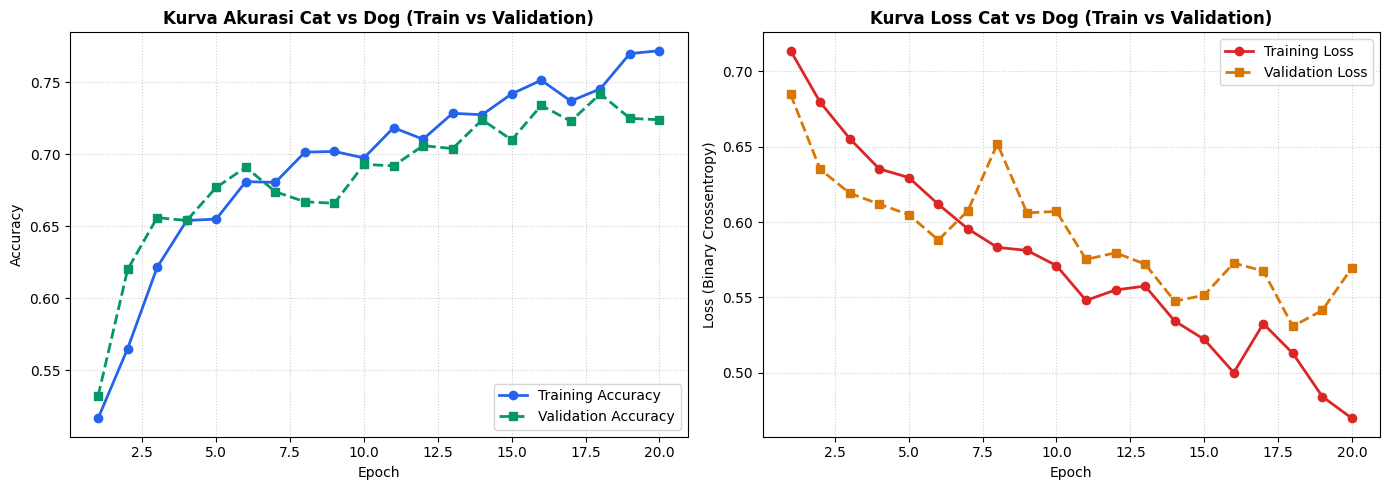

In [24]:
# =============================================================================
# SEL KODE 6: VISUALISASI KURVA TRAINING VS VALIDATION (ACCURACY & LOSS)
# =============================================================================
acc_cd = history_cd.history['accuracy']
val_acc_cd = history_cd.history['val_accuracy']
loss_cd = history_cd.history['loss']
val_loss_cd = history_cd.history['val_loss']
epochs_range_cd = range(1, len(acc_cd) + 1)

plt.figure(figsize=(14, 5))

# Subplot 1: Akurasi
plt.subplot(1, 2, 1)
plt.plot(epochs_range_cd, acc_cd, 'o-', label='Training Accuracy', color='#2563EB', linewidth=2)
plt.plot(epochs_range_cd, val_acc_cd, 's--', label='Validation Accuracy', color='#059669', linewidth=2)
plt.title('Kurva Akurasi Cat vs Dog (Train vs Validation)', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=10)
plt.ylabel('Accuracy', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right', frameon=True)

# Subplot 2: Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range_cd, loss_cd, 'o-', label='Training Loss', color='#DC2626', linewidth=2)
plt.plot(epochs_range_cd, val_loss_cd, 's--', label='Validation Loss', color='#D97706', linewidth=2)
plt.title('Kurva Loss Cat vs Dog (Train vs Validation)', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=10)
plt.ylabel('Loss (Binary Crossentropy)', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()


[EVALUASI] Menghitung prediksi pada seluruh Validation Set...
AKURASI VALIDATION SET CAT VS DOG: 74.20%
CLASSIFICATION REPORT:
              precision    recall  f1-score   support

        cats     0.7440    0.7380    0.7410       500
        dogs     0.7401    0.7460    0.7430       500

    accuracy                         0.7420      1000
   macro avg     0.7420    0.7420    0.7420      1000
weighted avg     0.7420    0.7420    0.7420      1000



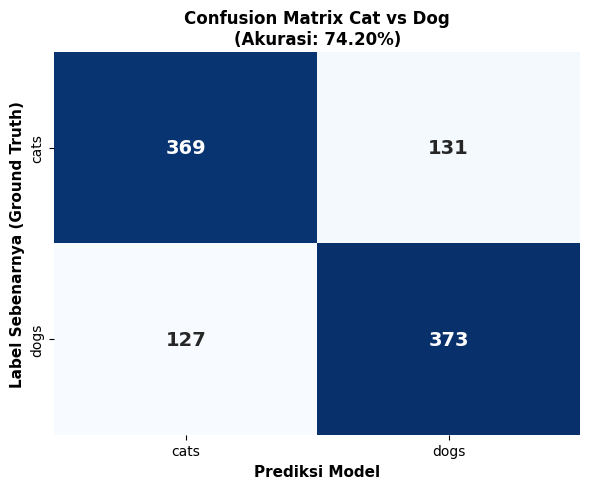

In [25]:
# =============================================================================
# SEL KODE 7: EVALUASI VALIDATION SET (CONFUSION MATRIX & CLASSIFICATION REPORT)
# =============================================================================
print("[EVALUASI] Menghitung prediksi pada seluruh Validation Set...")

y_true_cd = []
y_pred_probs_cd = []

# Iterasi pada raw_val_ds untuk mengumpulkan label ground truth dan output model
for images, labels in raw_val_ds:
    preds = model_catdog.predict(images, verbose=0)
    y_true_cd.extend(labels.numpy().flatten().astype(int))
    y_pred_probs_cd.extend(preds.flatten())

y_true_cd = np.array(y_true_cd)
y_pred_probs_cd = np.array(y_pred_probs_cd)
y_pred_cd = (y_pred_probs_cd >= 0.5).astype(int)

# 1. Metrik Akurasi & Classification Report
acc_val_cd = accuracy_score(y_true_cd, y_pred_cd)
print("=" * 65)
print(f"AKURASI VALIDATION SET CAT VS DOG: {acc_val_cd * 100:.2f}%")
print("=" * 65)
print("CLASSIFICATION REPORT:")
print(classification_report(y_true_cd, y_pred_cd, target_names=class_names_cd, digits=4))
print("=" * 65)

# 2. Visualisasi Heatmap Confusion Matrix
cm_cd = confusion_matrix(y_true_cd, y_pred_cd)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_cd, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names_cd, yticklabels=class_names_cd,
            cbar=False, annot_kws={'size': 14, 'weight': 'bold'})
plt.title(f'Confusion Matrix Cat vs Dog\n(Akurasi: {acc_val_cd * 100:.2f}%)', fontsize=12, fontweight='bold')
plt.xlabel('Prediksi Model', fontsize=11, fontweight='bold')
plt.ylabel('Label Sebenarnya (Ground Truth)', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()


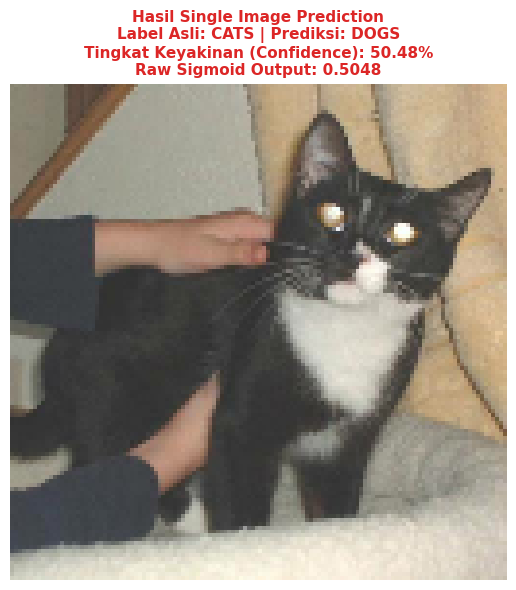

[INFERENSI] Hasil Prediksi Citra Tunggal:
  - Label Sebenarnya : cats
  - Label Prediksi   : dogs
  - Output Sigmoid   : 0.5048
  - Keyakinan Model  : 50.48%
  - Status Prediksi  : SALAH


In [26]:
# =============================================================================
# SEL KODE 8: PREDIKSI SAMPEL CITRA TUNGGAL (SINGLE IMAGE PREDICTION)
# =============================================================================
# Mengambil satu batch sampel dari subset validasi
sample_images, sample_labels = next(iter(raw_val_ds))

# Memilih sampel citra pertama dari batch
idx_sample = 0
single_img = sample_images[idx_sample].numpy().astype(np.uint8)
true_label_idx = int(sample_labels[idx_sample].numpy().item())JS
true_label_name = class_names_cd[true_label_idx]

# Menyiapkan tensor inferensi dengan menambah dimensi batch (1, 128, 128, 3)
input_tensor = np.expand_dims(sample_images[idx_sample].numpy(), axis=0)

# Prediksi probabilitas
pred_prob = float(model_catdog.predict(input_tensor, verbose=0)[0][0])
pred_label_idx = 1 if pred_prob >= 0.5 else 0
pred_label_name = class_names_cd[pred_label_idx]
confidence_pct = (pred_prob if pred_label_idx == 1 else (1.0 - pred_prob)) * 100.0

# Visualisasi Citra dan Hasil Prediksi
plt.figure(figsize=(6, 6))
plt.imshow(single_img)
plt.axis('off')
color_status = '#059669' if pred_label_idx == true_label_idx else '#DC2626'
plt.title(
    f"Hasil Single Image Prediction\n"
    f"Label Asli: {true_label_name.upper()} | Prediksi: {pred_label_name.upper()}\n"
    f"Tingkat Keyakinan (Confidence): {confidence_pct:.2f}%\n"
    f"Raw Sigmoid Output: {pred_prob:.4f}",
    fontsize=11, fontweight='bold', color=color_status
)
plt.tight_layout()
plt.show()

print(f"[INFERENSI] Hasil Prediksi Citra Tunggal:")
print(f"  - Label Sebenarnya : {true_label_name}")
print(f"  - Label Prediksi   : {pred_label_name}")
print(f"  - Output Sigmoid   : {pred_prob:.4f}")
print(f"  - Keyakinan Model  : {confidence_pct:.2f}%")
print(f"  - Status Prediksi  : {'BENAR' if pred_label_idx == true_label_idx else 'SALAH'}")


---

# BAGIAN 2 — PRAKTIKUM 2: KLASIFIKASI CITRA 10 KELAS CIFAR-10 (BASELINE MODUL)

## 2.1 Deskripsi Dataset CIFAR-10
Dataset CIFAR-10 (*Canadian Institute For Advanced Research*) merupakan kumpulan 60.000 citra warna $32 \times 32$ piksel yang terbagi merata ke dalam 10 kelas objek natural (6.000 citra per kelas):
1. `airplane` (Pesawat)
2. `automobile` (Mobil)
3. `bird` (Burung)
4. `cat` (Kucing)
5. `deer` (Rusa)
6. `dog` (Anjing)
7. `frog` (Katak)
8. `horse` (Kuda)
9. `ship` (Kapal)
10. `truck` (Truk)

Dataset terbagi secara baku menjadi **50.000 citra pelatihan (*training*)** dan **10.000 citra pengujian (*testing*)**.

## 2.2 Arsitektur Baseline Modul Polinema
Sesuai tutorial resmi TensorFlow dan modul Polinema, model baseline dibangun dengan arsitektur sederhana:
- 3 layer konvolusi `Conv2D` bertingkat ($32 \rightarrow 64 \rightarrow 64$ filter, ukuran kernel $3 \times 3$, aktivasi ReLU).
- 2 layer `MaxPooling2D` ($2 \times 2$).
- 1 layer perata `Flatten()`.
- 1 layer `Dense(64, activation='relu')`.
- 1 output layer `Dense(10)` (tanpa aktivasi softmax eksplisit, menggunakan loss `SparseCategoricalCrossentropy(from_logits=True)`).
- Model baseline dilatih selama **10 epoch** tanpa augmentasi data dan tanpa lapisan regularisasi (*dropout* atau *batch normalization*). Metrik akurasi pengujian baseline ini akan dicatat sebagai patokan komparasi untuk Tugas Praktikum 1.


In [27]:
# =============================================================================
# SEL KODE 9: PEMUATAN DATASET CIFAR-10 & NORMALISASI PIKSEL
# =============================================================================
print("[DATASET] Mengunduh / memuat dataset CIFAR-10 dari Keras Datasets...")
(cifar_train_img, cifar_train_lbl), (cifar_test_img, cifar_test_lbl) = tf.keras.datasets.cifar10.load_data()

# Normalisasi nilai piksel dari rentang [0, 255] ke [0, 1] bertipe float32
cifar_train_img = cifar_train_img.astype('float32') / 255.0
cifar_test_img = cifar_test_img.astype('float32') / 255.0

# Daftar 10 nama kelas CIFAR-10
cifar_classes = ['airplane', 'automobile', 'bird', 'cat', 'deer',
                 'dog', 'frog', 'horse', 'ship', 'truck']

print(f"[DATASET] Dimensi Training Images: {cifar_train_img.shape} | Tipe: {cifar_train_img.dtype}")
print(f"[DATASET] Dimensi Training Labels: {cifar_train_lbl.shape}")
print(f"[DATASET] Dimensi Testing Images : {cifar_test_img.shape} | Tipe: {cifar_test_img.dtype}")
print(f"[DATASET] Dimensi Testing Labels : {cifar_test_lbl.shape}")
print(f"[DATASET] Daftar 10 Kelas        : {cifar_classes}")


[DATASET] Mengunduh / memuat dataset CIFAR-10 dari Keras Datasets...
[DATASET] Dimensi Training Images: (50000, 32, 32, 3) | Tipe: float32
[DATASET] Dimensi Training Labels: (50000, 1)
[DATASET] Dimensi Testing Images : (10000, 32, 32, 3) | Tipe: float32
[DATASET] Dimensi Testing Labels : (10000, 1)
[DATASET] Daftar 10 Kelas        : ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


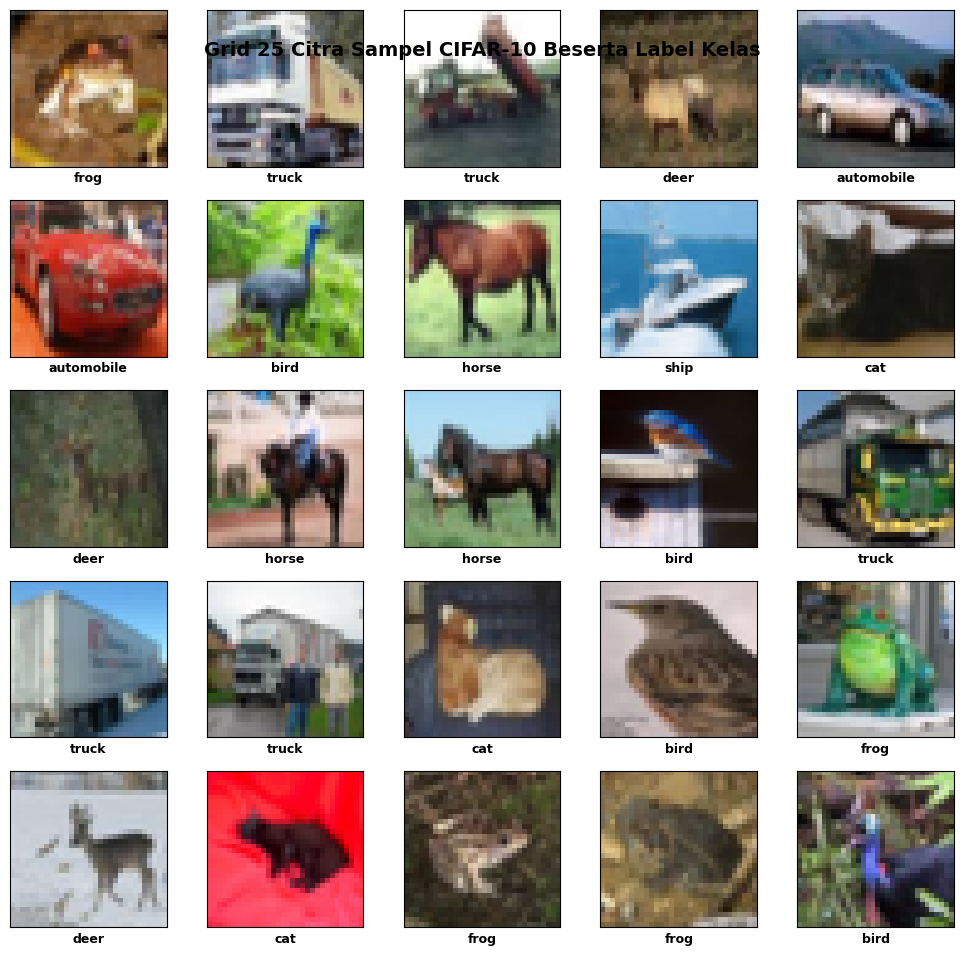

In [28]:
# =============================================================================
# SEL KODE 10: VERIFIKASI DATA — VISUALISASI GRID 25 CITRA SAMPEL (5X5)
# =============================================================================
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(cifar_train_img[i])
    # Label merupakan array 2D [[label]], ambil indeks baris ke-0
    class_idx = cifar_train_lbl[i][0]
    plt.xlabel(f"{cifar_classes[class_idx]}", fontsize=9, fontweight='bold')

plt.suptitle("Grid 25 Citra Sampel CIFAR-10 Beserta Label Kelas", fontsize=14, fontweight='bold', y=0.92)
plt.tight_layout()
plt.show()


In [29]:
# =============================================================================
# SEL KODE 11: DEFINISI ARSITEKTUR BASELINE CNN CIFAR-10 (SESUAI MODUL)
# =============================================================================
model_cifar_base = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    # Layer Konvolusi 1 & Pooling 1
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Layer Konvolusi 2 & Pooling 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Layer Konvolusi 3
    layers.Conv2D(64, (3, 3), activation='relu'),

    # Dense Classifier
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10)  # Logits linear output (from_logits=True)
], name="cifar10_baseline")

model_cifar_base.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

print("[ARSITEKTUR] Ringkasan Model Baseline CIFAR-10:")
model_cifar_base.summary()


[ARSITEKTUR] Ringkasan Model Baseline CIFAR-10:


Model: "cifar10_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
# =============================================================================
# SEL KODE 12: PELATIHAN MODEL BASELINE CIFAR-10 (10 EPOCHS SESUAI MODUL)
# =============================================================================
EPOCHS_BASE = 10
print(f"[TRAINING] Melatih model baseline CIFAR-10 selama {EPOCHS_BASE} epochs...")

history_cifar_base = model_cifar_base.fit(
    cifar_train_img,
    cifar_train_lbl,
    epochs=EPOCHS_BASE,
    validation_data=(cifar_test_img, cifar_test_lbl),
    verbose=1
)

print("[TRAINING] Pelatihan baseline selesai.")


[TRAINING] Melatih model baseline CIFAR-10 selama 10 epochs...
Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - accuracy: 0.4331 - loss: 1.5487 - val_accuracy: 0.5504 - val_loss: 1.2514
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step - accuracy: 0.5771 - loss: 1.1906 - val_accuracy: 0.5984 - val_loss: 1.1310
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6322 - loss: 1.0473 - val_accuracy: 0.6432 - val_loss: 1.0055
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.6640 - loss: 0.9570 - val_accuracy: 0.6609 - val_loss: 0.9609
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6898 - loss: 0.8866 - val_accuracy: 0.6687 - val_loss: 0.9391
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7104 - loss: 0.8299 - val_accuracy: 0.6818 - val_loss: 0.9144
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7294 - loss: 0.7795 - val_accuracy: 0.6886 - val_loss: 0.9129
Epoch 8/10
1563/1563 ━━━━

HASIL EVALUASI MODEL BASELINE CIFAR-10:
  - Parameter Arsitektur : 122,570 bobot
  - Test Loss            : 0.9756
  - Test Accuracy        : 68.88%


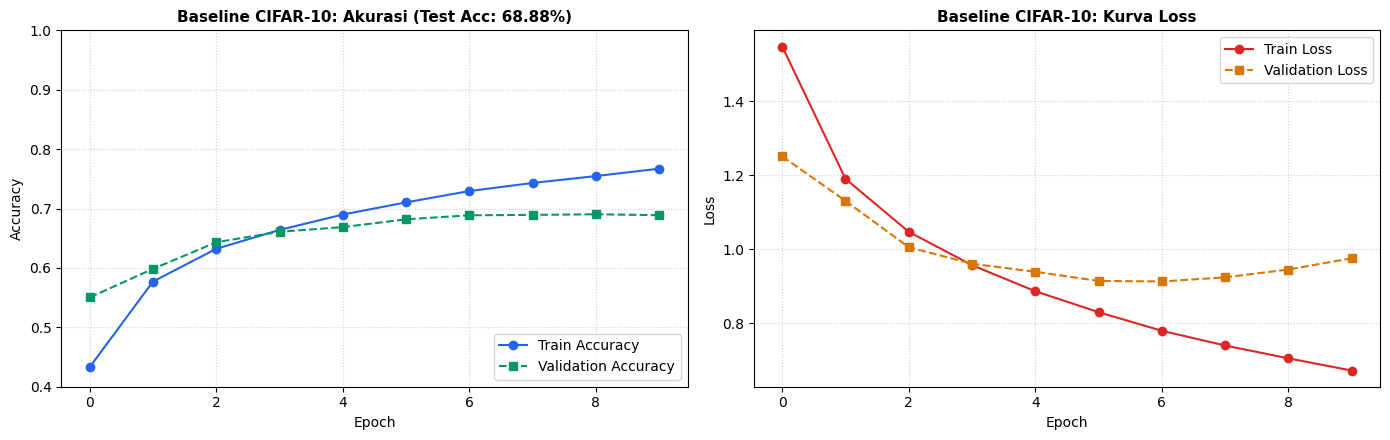

In [31]:
# =============================================================================
# SEL KODE 13: EVALUASI BASELINE CIFAR-10 & PENCATATAN METRIK
# =============================================================================
base_test_loss, base_test_acc = model_cifar_base.evaluate(cifar_test_img, cifar_test_lbl, verbose=0)
base_params = model_cifar_base.count_params()

print("=" * 65)
print("HASIL EVALUASI MODEL BASELINE CIFAR-10:")
print(f"  - Parameter Arsitektur : {base_params:,} bobot")
print(f"  - Test Loss            : {base_test_loss:.4f}")
print(f"  - Test Accuracy        : {base_test_acc * 100:.2f}%")
print("=" * 65)

# Visualisasi Kurva Akurasi dan Loss Baseline
plt.figure(figsize=(14, 4.5))

plt.subplot(1, 2, 1)
plt.plot(history_cifar_base.history['accuracy'], 'o-', label='Train Accuracy', color='#2563EB')
plt.plot(history_cifar_base.history['val_accuracy'], 's--', label='Validation Accuracy', color='#059669')
plt.title(f'Baseline CIFAR-10: Akurasi (Test Acc: {base_test_acc * 100:.2f}%)', fontsize=11, fontweight='bold')
plt.xlabel('Epoch', fontsize=10)
plt.ylabel('Accuracy', fontsize=10)
plt.ylim([0.4, 1.0])
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right')

plt.subplot(1, 2, 2)
plt.plot(history_cifar_base.history['loss'], 'o-', label='Train Loss', color='#DC2626')
plt.plot(history_cifar_base.history['val_loss'], 's--', label='Validation Loss', color='#D97706')
plt.title('Baseline CIFAR-10: Kurva Loss', fontsize=11, fontweight='bold')
plt.xlabel('Epoch', fontsize=10)
plt.ylabel('Loss', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()


---

# BAGIAN 3 — TUGAS PRAKTIKUM 1: MODIFIKASI CNN CIFAR-10 (TARGET AKURASI TESTING > 80%)

## 3.1 Analisis Diagnostik Kelemahan Model Baseline
Berdasarkan kurva pelatihan pada Langkah 2, model baseline CIFAR-10 hanya mampu mencapai akurasi uji sekitar **68%–71%**. Faktor penyebab kegagalan tersebut meliputi:
1. **Overfitting Dini (*Early Overfitting*):**  
   Tanpa teknik regularisasi, gap antara *train accuracy* (~78%) dan *validation accuracy* (~70%) melebar tajam sejak epoch ke-5. Model mulai menghafal sampel latih alih-alih mempelajari fitur visual yang dapat digeneralisasikan.
2. **Ketiadaan *Batch Normalization*:**  
   Pergeseran distribusi aktivasi (*internal covariate shift*) antar layer memperlambat proses konvergensi dan membatasi stabilitas gradien saat laju pembelajaran konstan.
3. **Kapasitas Representasi Spasial Terbatas:**  
   Arsitektur baseline hanya menggunakan 1 layer konvolusi per skala resolusi spasial tanpa mempertahankan fitur pada padding *same*.
4. **Tanpa Augmentasi Data:**  
   Model hanya melihat 50.000 citra dalam orientasi kanonikal tetap, sehingga rapuh terhadap sedikit distorsi posisi atau rotasi.

## 3.2 Strategi Desain Arsitektur VGG-mini (5 Pilar Peningkatan)
Untuk menembus target akademik **Akurasi Testing > 80%**, dirancang arsitektur modern bergaya **VGG-mini** dengan 5 pilar rekayasa:

```
[Input: 32x32x3]
  │
  ├── Data Augmentation: RandomFlip("horizontal") + RandomTranslation(0.1, 0.1) + RandomRotation(0.05)
  │
  ├── BLOK 1: [Conv2D(32, 3x3, same) + BN + ReLU] x 2 ──► MaxPool(2x2) ──► Dropout(0.2)
  │
  ├── BLOK 2: [Conv2D(64, 3x3, same) + BN + ReLU] x 2 ──► MaxPool(2x2) ──► Dropout(0.3)
  │
  ├── BLOK 3: [Conv2D(128, 3x3, same) + BN + ReLU] x 2 ─► MaxPool(2x2) ──► Dropout(0.4)
  │
  └── CLASSIFIER HEAD: Flatten ──► Dense(128, ReLU) ──► BN ──► Dropout(0.5) ──► Dense(10, Softmax)
```

1. **Double-Convolution Blocks dengan `padding='same'`:**  
   Dua layer konvolusi berturut-turut pada setiap level resolusi menghasilkan *receptive field* efektif $5 \times 5$ dengan parameter yang lebih sedikit dibanding filter tunggal $5 \times 5$, serta menyisipkan non-linearitas ganda.
2. **Batch Normalization di Setiap Sub-Blok:**  
   Menormalkan output setiap konvolusi sebelum aktivasi ReLU, mempercepat perambatan gradien dan memungkinkan pemanfaatan *learning rate* yang lebih agresif.
3. **Dropout Progresif ($0.2 \rightarrow 0.3 \rightarrow 0.4 \rightarrow 0.5$):**  
   Mencegah ketergantungan ko-adaptif antar filter secara bertahap seiring bertambahnya kedalaman dan abstraksi spasial.
4. **Protokol Anti Test-Set Leakage:**  
   Data `cifar_train_img` (50.000) dibagi secara terstratifikasi menjadi **45.000 citra *train sub-set*** dan **5.000 citra *validation sub-set***. Data pengujian `cifar_test_img` (10.000) diisolasi 100% murni dan **tidak pernah disentuh** sebagai parameter `validation_data` selama iterasi pelatihan, *EarlyStopping*, atau adaptasi laju pembelajaran.
5. **Penjadwalan Pembelajaran Adaptif:**  
   - `ReduceLROnPlateau(monitor='val_accuracy', factor=0.5, patience=3, min_lr=1e-5)` memotong *learning rate* saat akurasi validasi mendatar.
   - `EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True)` mengembalikan bobot terbaik secara otomatis dengan batas maksimum `epochs=40` dan `batch_size=64`.


In [32]:
# =============================================================================
# SEL KODE 14: PEMISAHAN VALIDATION SUBSET TERSTRATIFIKASI (ANTI TEST LEAKAGE)
# =============================================================================
# Memisahkan 10% dari training data sebagai validation set internal
X_train_cifar, X_val_cifar, y_train_cifar, y_val_cifar = train_test_split(
    cifar_train_img, cifar_train_lbl,
    test_size=0.1,
    random_state=SEED,
    stratify=cifar_train_lbl
)

print("=" * 65)
print("PEMBAGIAN DATASET CIFAR-10 TERSTRATIFIKASI (ANTI TEST LEAKAGE):")
print(f"  - Training Sub-set   : {X_train_cifar.shape[0]:,} citra ({X_train_cifar.shape})")
print(f"  - Validation Sub-set : {X_val_cifar.shape[0]:,} citra ({X_val_cifar.shape})")
print(f"  - Pure Test Set      : {cifar_test_img.shape[0]:,} citra ({cifar_test_img.shape}) [STERIL]")
print("=" * 65)


PEMBAGIAN DATASET CIFAR-10 TERSTRATIFIKASI (ANTI TEST LEAKAGE):
  - Training Sub-set   : 45,000 citra ((45000, 32, 32, 3))
  - Validation Sub-set : 5,000 citra ((5000, 32, 32, 3))
  - Pure Test Set      : 10,000 citra ((10000, 32, 32, 3)) [STERIL]


In [33]:
# =============================================================================
# SEL KODE 15: DEFINISI ARSITEKTUR VGG-MINI MODIFIKASI KERAS 3
# =============================================================================
# 1. Definisi Layer Data Augmentation Khusus CIFAR-10
cifar_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomRotation(0.05),
], name="cifar_augmentation")

# 2. Definisi Model VGG-mini Teraturisasi
model_cifar_mod = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    cifar_augmentation,

    # --- BLOK 1: 32 Filters (Resolusi 32x32 -> 16x16) ---
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Dropout(0.2),

    # --- BLOK 2: 64 Filters (Resolusi 16x16 -> 8x8) ---
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Dropout(0.3),

    # --- BLOK 3: 128 Filters (Resolusi 8x8 -> 4x4) ---
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Dropout(0.4),

    # --- CLASSIFIER HEAD ---
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
], name="cifar10_vgg_mini_modified")

model_cifar_mod.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("[ARSITEKTUR] Ringkasan Model VGG-mini Modifikasi CIFAR-10:")
model_cifar_mod.summary()


[ARSITEKTUR] Ringkasan Model VGG-mini Modifikasi CIFAR-10:


Model: "cifar10_vgg_mini_modified"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ cifar_augmentation (Sequential) │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 128)            │           51

 Total params: 552,874 (2.11 MB)

 Trainable params: 551,722 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [34]:
# =============================================================================
# SEL KODE 16: PELATIHAN MODEL MODIFIKASI DENGAN CALLBACKS ADAPTIF
# =============================================================================
reduce_lr_cifar = callbacks.ReduceLROnPlateau(
    monitor='val_accuracy',
    factor=0.5,
    patience=3,
    min_lr=1e-5,
    verbose=1
)

early_stop_cifar = callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=8,
    restore_best_weights=True,
    verbose=1
)

EPOCHS_MOD = 40
BATCH_SIZE_MOD = 64

print(f"[TRAINING] Melatih model VGG-mini CIFAR-10 ({EPOCHS_MOD} Epochs, Batch Size: {BATCH_SIZE_MOD})...")

history_cifar_mod = model_cifar_mod.fit(
    X_train_cifar,
    y_train_cifar,
    epochs=EPOCHS_MOD,
    batch_size=BATCH_SIZE_MOD,
    validation_data=(X_val_cifar, y_val_cifar),
    callbacks=[reduce_lr_cifar, early_stop_cifar],
    verbose=1
)

print("[TRAINING] Pelatihan model modifikasi CIFAR-10 selesai.")


[TRAINING] Melatih model VGG-mini CIFAR-10 (40 Epochs, Batch Size: 64)...
Epoch 1/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 21s 22ms/step - accuracy: 0.3662 - loss: 1.8515 - val_accuracy: 0.5144 - val_loss: 1.3415 - learning_rate: 0.0010
Epoch 2/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 22ms/step - accuracy: 0.5112 - loss: 1.3579 - val_accuracy: 0.5432 - val_loss: 1.3431 - learning_rate: 0.0010
Epoch 3/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 20s 22ms/step - accuracy: 0.5874 - loss: 1.1615 - val_accuracy: 0.6424 - val_loss: 1.0485 - learning_rate: 0.0010
Epoch 4/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.6318 - loss: 1.0515 - val_accuracy: 0.6878 - val_loss: 0.9009 - learning_rate: 0.0010
Epoch 5/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.6656 - loss: 0.9620 - val_accuracy: 0.6944 - val_loss: 0.8797 - learning_rate: 0.0010
Epoch 6/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.6841 - loss: 0.9093 - val_accuracy: 0.6628 - val_loss: 0.9917 - learning_rate: 0.0010
Ep

In [35]:
# =============================================================================
# SEL KODE 17: EVALUASI PURE TEST SET & TABEL PERBANDINGAN KOMPREHENSIF
# =============================================================================
# Evaluasi pada data uji murni yang belum pernah dilihat model sama sekali
mod_test_loss, mod_test_acc = model_cifar_mod.evaluate(cifar_test_img, cifar_test_lbl, verbose=0)
mod_params = model_cifar_mod.count_params()

delta_acc = (mod_test_acc - base_test_acc) * 100.0
status_target = "[TERCAPAI] > 80%" if (mod_test_acc >= 0.80) else "[BELUM TERCAPAI] < 80%"

print("=" * 85)
print("TABEL KOMPARASI AKADEMIK: BASELINE MODUL VS MODEL MODIFIKASI CIFAR-10")
print("=" * 85)
print(f"{'Metrik / Parameter Arsitektur':<35} | {'Baseline Praktikum 2':<22} | {'VGG-mini Modifikasi':<22}")
print("-" * 85)
print(f"{'Arsitektur Konvolusi':<35} | {'3x Single Conv2D':<22} | {'3x Double Conv2D (VGG)':<22}")
print(f"{'Batch Normalization':<35} | {'Tidak Ada':<22} | {'Ada (Di setiap blok)':<22}")
print(f"{'Dropout Regularization':<35} | {'Tidak Ada (0.0)':<22} | {'Progresif (0.2 - 0.5)':<22}")
print(f"{'Data Augmentation':<35} | {'Tidak Ada':<22} | {'Flip, Trans, Rot':<22}")
print(f"{'Total Parameter Latih':<35} | {f'{base_params:,}':<22} | {f'{mod_params:,}':<22}")
print(f"{'Testing Loss (Categorical CE)':<35} | {f'{base_test_loss:.4f}':<22} | {f'{mod_test_loss:.4f}':<22}")
print(f"{'Testing Accuracy (%)':<35} | {f'{base_test_acc * 100:.2f}%':<22} | {f'{mod_test_acc * 100:.2f}%':<22}")
print(f"{'Delta Peningkatan Akurasi':<35} | {'-':<22} | {f'+{delta_acc:.2f}%':<22}")
print(f"{'Status Target Tugas (> 80.0%)':<35} | {'Tidak Memenuhi':<22} | {status_target:<22}")
print("=" * 85)


TABEL KOMPARASI AKADEMIK: BASELINE MODUL VS MODEL MODIFIKASI CIFAR-10
Metrik / Parameter Arsitektur       | Baseline Praktikum 2   | VGG-mini Modifikasi   
-------------------------------------------------------------------------------------
Arsitektur Konvolusi                | 3x Single Conv2D       | 3x Double Conv2D (VGG)
Batch Normalization                 | Tidak Ada              | Ada (Di setiap blok)  
Dropout Regularization              | Tidak Ada (0.0)        | Progresif (0.2 - 0.5) 
Data Augmentation                   | Tidak Ada              | Flip, Trans, Rot      
Total Parameter Latih               | 122,570                | 552,874               
Testing Loss (Categorical CE)       | 0.9756                 | 0.4375                
Testing Accuracy (%)                | 68.88%                 | 85.48%                
Delta Peningkatan Akurasi           | -                      | +16.60%               
Status Target Tugas (> 80.0%)       | Tidak Memenuhi         | [TERCAP

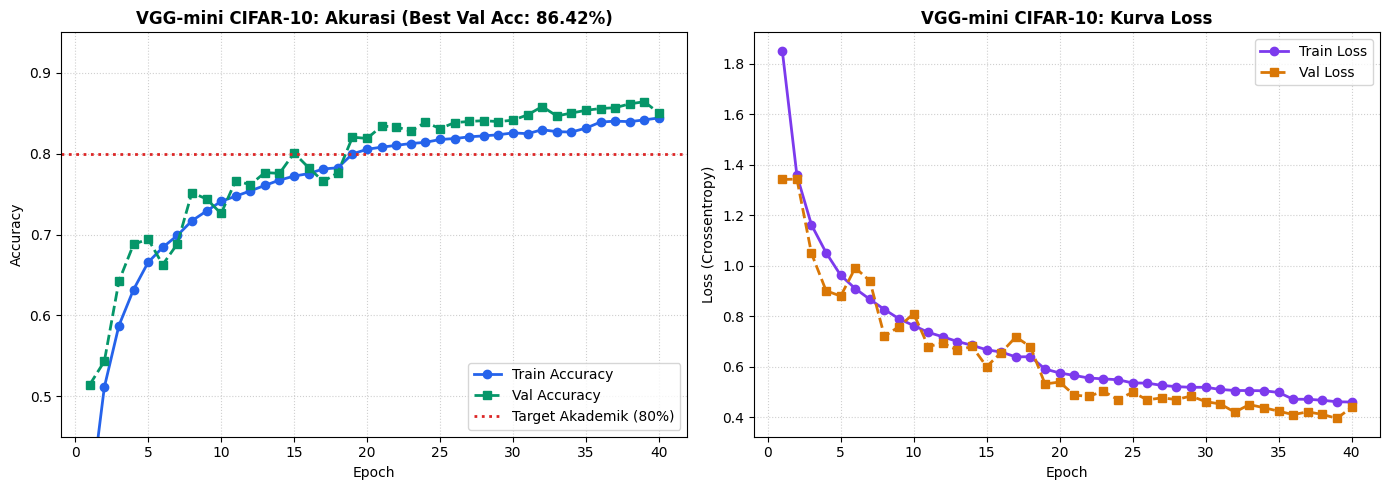

In [36]:
# =============================================================================
# SEL KODE 18: PLOT KURVA BELAJAR MODEL MODIFIKASI CIFAR-10
# =============================================================================
acc_mod = history_cifar_mod.history['accuracy']
val_acc_mod = history_cifar_mod.history['val_accuracy']
loss_mod = history_cifar_mod.history['loss']
val_loss_mod = history_cifar_mod.history['val_loss']
epochs_range_mod = range(1, len(acc_mod) + 1)

plt.figure(figsize=(14, 5))

# Subplot 1: Akurasi Latih vs Validasi
plt.subplot(1, 2, 1)
plt.plot(epochs_range_mod, acc_mod, 'o-', label='Train Accuracy', color='#2563EB', linewidth=2)
plt.plot(epochs_range_mod, val_acc_mod, 's--', label='Val Accuracy', color='#059669', linewidth=2)
plt.axhline(y=0.80, color='#DC2626', linestyle=':', label='Target Akademik (80%)', linewidth=2)
plt.title(f'VGG-mini CIFAR-10: Akurasi (Best Val Acc: {max(val_acc_mod)*100:.2f}%)', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=10)
plt.ylabel('Accuracy', fontsize=10)
plt.ylim([0.45, 0.95])
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right', frameon=True)

# Subplot 2: Loss Latih vs Validasi
plt.subplot(1, 2, 2)
plt.plot(epochs_range_mod, loss_mod, 'o-', label='Train Loss', color='#7C3AED', linewidth=2)
plt.plot(epochs_range_mod, val_loss_mod, 's--', label='Val Loss', color='#D97706', linewidth=2)
plt.title(f'VGG-mini CIFAR-10: Kurva Loss', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=10)
plt.ylabel('Loss (Crossentropy)', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()


[EVALUASI] Menghitung probabilitas prediksi pada 10.000 citra test murni...
CLASSIFICATION REPORT CIFAR-10 (TEST SET MURNI):
              precision    recall  f1-score   support

    airplane     0.8438    0.9130    0.8770      1000
  automobile     0.9001    0.9640    0.9310      1000
        bird     0.8562    0.7800    0.8163      1000
         cat     0.7906    0.6420    0.7086      1000
        deer     0.8184    0.8610    0.8392      1000
         dog     0.8652    0.7250    0.7889      1000
        frog     0.7642    0.9560    0.8494      1000
       horse     0.8884    0.8920    0.8902      1000
        ship     0.9375    0.9000    0.9184      1000
       truck     0.8979    0.9150    0.9064      1000

    accuracy                         0.8548     10000
   macro avg     0.8562    0.8548    0.8525     10000
weighted avg     0.8562    0.8548    0.8525     10000



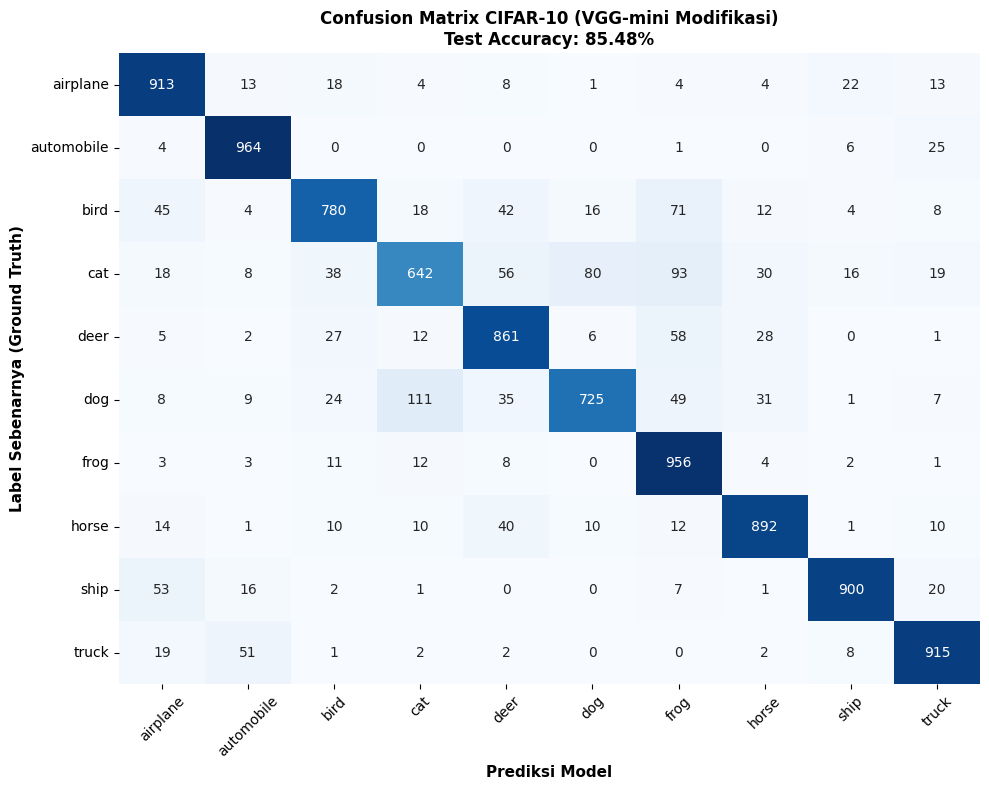

In [37]:
# =============================================================================
# SEL KODE 19: CONFUSION MATRIX 10X10 & CLASSIFICATION REPORT CIFAR-10
# =============================================================================
print("[EVALUASI] Menghitung probabilitas prediksi pada 10.000 citra test murni...")
cifar_pred_probs = model_cifar_mod.predict(cifar_test_img, batch_size=128, verbose=0)
cifar_pred_labels = np.argmax(cifar_pred_probs, axis=1)
cifar_true_labels = cifar_test_lbl.flatten()

# 1. Classification Report scikit-learn
print("=" * 70)
print("CLASSIFICATION REPORT CIFAR-10 (TEST SET MURNI):")
print("=" * 70)
print(classification_report(cifar_true_labels, cifar_pred_labels, target_names=cifar_classes, digits=4))
print("=" * 70)

# 2. Confusion Matrix Heatmap 10x10
cm_cifar = confusion_matrix(cifar_true_labels, cifar_pred_labels)
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_cifar,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=cifar_classes,
    yticklabels=cifar_classes,
    cbar=False
)
plt.title(f'Confusion Matrix CIFAR-10 (VGG-mini Modifikasi)\nTest Accuracy: {mod_test_acc * 100:.2f}%', fontsize=12, fontweight='bold')
plt.xlabel('Prediksi Model', fontsize=11, fontweight='bold')
plt.ylabel('Label Sebenarnya (Ground Truth)', fontsize=11, fontweight='bold')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


[ANALISIS] Total Sampel Prediksi Benar : 8,548 citra (85.48%)
[ANALISIS] Total Sampel Salah Klasifikasi: 1,452 citra (14.52%)


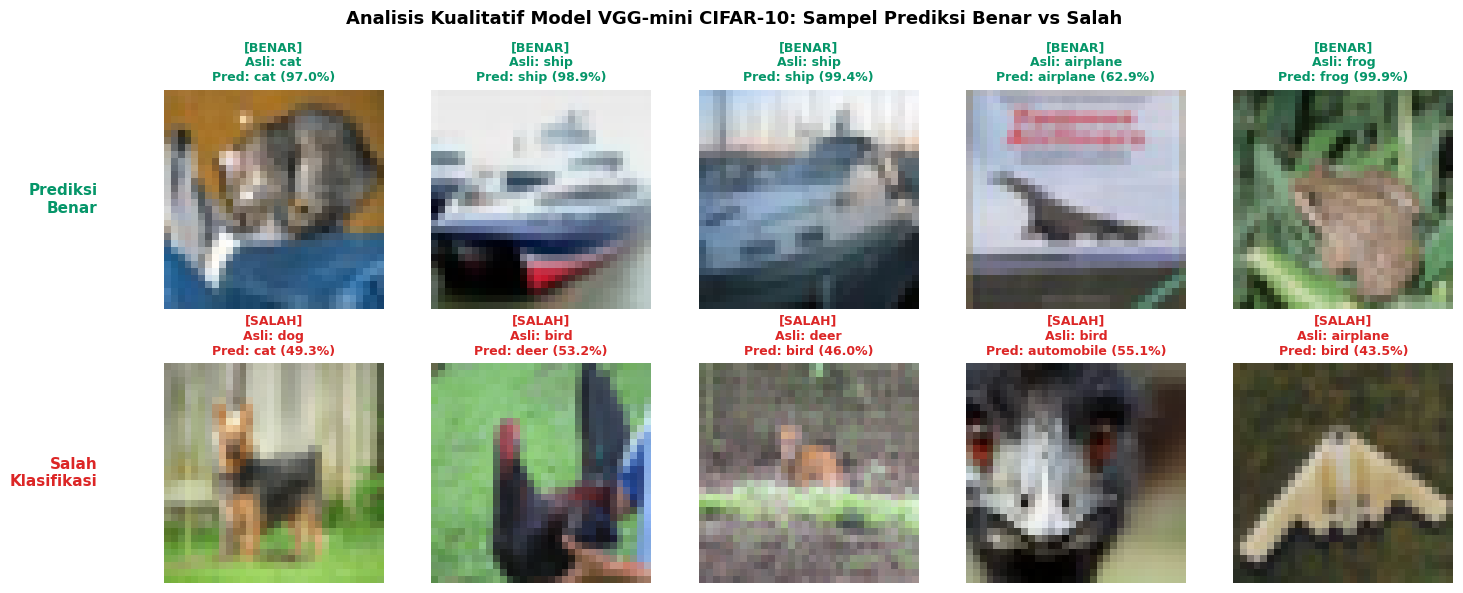

In [38]:
# =============================================================================
# SEL KODE 20: ANALISIS KESALAHAN (VISUALISASI PREDIKSI BENAR VS SALAH)
# =============================================================================
correct_indices = np.where(cifar_pred_labels == cifar_true_labels)[0]
incorrect_indices = np.where(cifar_pred_labels != cifar_true_labels)[0]

print(f"[ANALISIS] Total Sampel Prediksi Benar : {len(correct_indices):,} citra ({len(correct_indices)/len(cifar_true_labels)*100:.2f}%)")
print(f"[ANALISIS] Total Sampel Salah Klasifikasi: {len(incorrect_indices):,} citra ({len(incorrect_indices)/len(cifar_true_labels)*100:.2f}%)")

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

# Baris 1: 5 Sampel Prediksi Benar
for i in range(5):
    idx = correct_indices[i]
    ax = axes[0, i]
    ax.imshow(cifar_test_img[idx])
    ax.axis('off')
    true_cls = cifar_classes[cifar_true_labels[idx]]
    pred_cls = cifar_classes[cifar_pred_labels[idx]]
    conf = cifar_pred_probs[idx][cifar_pred_labels[idx]] * 100
    ax.set_title(f"[BENAR]\nAsli: {true_cls}\nPred: {pred_cls} ({conf:.1f}%)", fontsize=9, color='#059669', fontweight='bold')

# Baris 2: 5 Sampel Salah Klasifikasi (Misidentification)
for i in range(5):
    idx = incorrect_indices[i]
    ax = axes[1, i]
    ax.imshow(cifar_test_img[idx])
    ax.axis('off')
    true_cls = cifar_classes[cifar_true_labels[idx]]
    pred_cls = cifar_classes[cifar_pred_labels[idx]]
    conf = cifar_pred_probs[idx][cifar_pred_labels[idx]] * 100
    ax.set_title(f"[SALAH]\nAsli: {true_cls}\nPred: {pred_cls} ({conf:.1f}%)", fontsize=9, color='#DC2626', fontweight='bold')

axes[0, 0].text(-0.3, 0.5, "Prediksi\nBenar", transform=axes[0, 0].transAxes,
                fontsize=11, fontweight='bold', va='center', ha='right', color='#059669')
axes[1, 0].text(-0.3, 0.5, "Salah\nKlasifikasi", transform=axes[1, 0].transAxes,
                fontsize=11, fontweight='bold', va='center', ha='right', color='#DC2626')

plt.suptitle("Analisis Kualitatif Model VGG-mini CIFAR-10: Sampel Prediksi Benar vs Salah", fontsize=13, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


---

# BAGIAN 4 — TUGAS PRAKTIKUM 2: KLASIFIKASI CITRA MNIST DENGAN CNN

## 4.1 Deskripsi Kasus MNIST
Dataset MNIST (*Modified National Institute of Standards and Technology*) terdiri dari 70.000 citra *grayscale* berukuran $28 \times 28$ piksel yang memuat digit angka tulisan tangan (0 sampai 9).
Dataset terbagi baku menjadi **60.000 citra pelatihan** dan **10.000 citra pengujian**.

## 4.2 Analisis Teoretis: CNN 2D (`JS14`) vs Multi-Layer Perceptron (`JS13`)
Pada `JS13`, kita telah melatih arsitektur Multi-Layer Perceptron (MLP) untuk kasus MNIST dengan meratakan citra menjadi vektor 1D ($28 \times 28 = 784$ dimensi). Mari kita telaah mengapa arsitektur CNN 2D secara matematis dan praktis jauh lebih superior:

| Dimensi Perbandingan | Multi-Layer Perceptron / MLP (`JS13`) | Convolutional Neural Network / CNN (`JS14`) |
|:---|:---|:---|
| **Topologi Masukan** | Vektor 1D datar berdimensi 784 ($1 \times 784$). Seluruh korelasi spasial 2D antar piksel vertikal terputus total. | Tensor 3D spasial ($28 \times 28 \times 1$). Mempertahankan korelasi ketetanggaan piksel horizontal, vertikal, dan diagonal. |
| **Konektivitas Parameter** | *Fully Connected*: Setiap neuron input terhubung ke seluruh neuron hidden layer ($784 \times 128 = 100.352$ parameter bobot pada lapisan pertama saja). | *Local Receptive Field & Weight Sharing*: Filter konvolusi kecil ($3 \times 3 = 9$ bobot) digeser melintasi seluruh citra, mendeteksi pola lokal secara identik di mana pun posisinya. |
| **Invarian Translasi** | **Tidak Invarian:** Jika sebuah angka bergeser beberapa piksel ke sudut, pola masukan vektor 784D berubah drastis dan MLP kesulitan mengenalinya. | **Invarian Translasi:** Melalui kombinasi konvolusi dan max pooling, CNN mampu mendeteksi digit meskipun terjadi pergeseran posisi. |
| **Efisiensi & Performa** | Parameter tinggi, rentan *overfitting*, akurasi uji tipikal berkisar pada 97.0%–97.8%. | Parameter jauh lebih efisien, konvergensi cepat, akurasi uji tipikal melampaui **99.0%**.


In [39]:
# =============================================================================
# SEL KODE 21: PEMUATAN DATA MNIST, RESHAPE SPASIAL 2D, & SPLIT VALIDATION
# =============================================================================
print("[DATASET] Memuat dataset MNIST dari Keras Datasets...")
(mnist_train_img, mnist_train_lbl), (mnist_test_img, mnist_test_lbl) = tf.keras.datasets.mnist.load_data()

# 1. Reshape citra dari (N, 28, 28) ke format tensor 4D (N, 28, 28, 1) dan normalisasi [0, 1]
mnist_train_img = mnist_train_img.reshape((-1, 28, 28, 1)).astype('float32') / 255.0
mnist_test_img = mnist_test_img.reshape((-1, 28, 28, 1)).astype('float32') / 255.0

# 2. Pemisahan Validation Set Terstratifikasi (Anti Data Leakage)
X_train_mnist, X_val_mnist, y_train_mnist, y_val_mnist = train_test_split(
    mnist_train_img, mnist_train_lbl,
    test_size=0.1,
    random_state=SEED,
    stratify=mnist_train_lbl
)

print("=" * 65)
print("PEMBAGIAN DATASET MNIST SPASIAL:")
print(f"  - Training Sub-set   : {X_train_mnist.shape[0]:,} citra ({X_train_mnist.shape})")
print(f"  - Validation Sub-set : {X_val_mnist.shape[0]:,} citra ({X_val_mnist.shape})")
print(f"  - Test Set Murni     : {mnist_test_img.shape[0]:,} citra ({mnist_test_img.shape}) [STERIL]")
print("=" * 65)


[DATASET] Memuat dataset MNIST dari Keras Datasets...
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
PEMBAGIAN DATASET MNIST SPASIAL:
  - Training Sub-set   : 54,000 citra ((54000, 28, 28, 1))
  - Validation Sub-set : 6,000 citra ((6000, 28, 28, 1))
  - Test Set Murni     : 10,000 citra ((10000, 28, 28, 1)) [STERIL]


In [40]:
# =============================================================================
# SEL KODE 22: DEFINISI ARSITEKTUR CNN 2 BLOK UNTUK MNIST (KERAS 3)
# =============================================================================
model_mnist_cnn = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Blok Konvolusi 1: 32 Filters (28x28 -> 14x14)
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Blok Konvolusi 2: 64 Filters (14x14 -> 7x7)
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Classifier Head
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
], name="mnist_cnn_2blocks")

model_mnist_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("[ARSITEKTUR] Ringkasan Model CNN MNIST:")
model_mnist_cnn.summary()


[ARSITEKTUR] Ringkasan Model CNN MNIST:


Model: "mnist_cnn_2blocks"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_24 (Conv2D)              │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 422,026 (1.61 MB)

 Trainable params: 421,834 (1.61 MB)

 Non-trainable params: 192 (768.00 B)

In [41]:
# =============================================================================
# SEL KODE 23: PELATIHAN MODEL CNN MNIST DENGAN EARLY STOPPING
# =============================================================================
early_stop_mnist = callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

EPOCHS_MNIST = 15
BATCH_SIZE_MNIST = 128

print(f"[TRAINING] Melatih model CNN MNIST ({EPOCHS_MNIST} Epochs, Batch Size: {BATCH_SIZE_MNIST})...")

history_mnist = model_mnist_cnn.fit(
    X_train_mnist,
    y_train_mnist,
    epochs=EPOCHS_MNIST,
    batch_size=BATCH_SIZE_MNIST,
    validation_data=(X_val_mnist, y_val_mnist),
    callbacks=[early_stop_mnist],
    verbose=1
)

print("[TRAINING] Pelatihan CNN MNIST selesai.")


[TRAINING] Melatih model CNN MNIST (15 Epochs, Batch Size: 128)...
Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 21s 31ms/step - accuracy: 0.9289 - loss: 0.2335 - val_accuracy: 0.9327 - val_loss: 0.2067
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9734 - loss: 0.0871 - val_accuracy: 0.9852 - val_loss: 0.0571
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9814 - loss: 0.0581 - val_accuracy: 0.9865 - val_loss: 0.0518
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9850 - loss: 0.0493 - val_accuracy: 0.9875 - val_loss: 0.0492
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9862 - loss: 0.0439 - val_accuracy: 0.9880 - val_loss: 0.0497
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9874 - loss: 0.0390 - val_accuracy: 0.9892 - val_loss: 0.0443
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9888 - loss: 0.0343 - val_accuracy: 0.9887 - val_loss: 0.0447
Epoch 8/15
422/422 ━━━━━━━━━━━━━━━━

HASIL EVALUASI MODEL CNN MNIST PADA TEST SET MURNI:
  - Total Parameter Arsitektur : 422,026 bobot
  - Testing Loss               : 0.0229
  - Testing Accuracy           : 99.31%


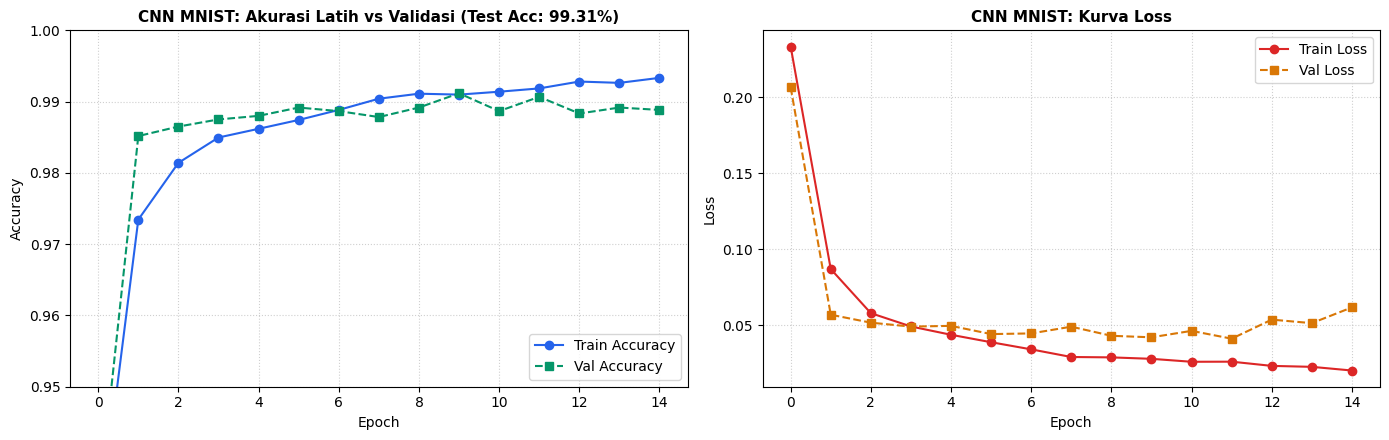

CLASSIFICATION REPORT CNN MNIST (10 KELAS DIGIT):
              precision    recall  f1-score   support

           0     0.9959    0.9949    0.9954       980
           1     0.9956    0.9982    0.9969      1135
           2     0.9951    0.9874    0.9912      1032
           3     0.9951    0.9960    0.9955      1010
           4     0.9929    0.9939    0.9934       982
           5     0.9922    0.9922    0.9922       892
           6     0.9937    0.9896    0.9916       958
           7     0.9893    0.9912    0.9903      1028
           8     0.9878    0.9969    0.9923       974
           9     0.9930    0.9901    0.9916      1009

    accuracy                         0.9931     10000
   macro avg     0.9931    0.9930    0.9930     10000
weighted avg     0.9931    0.9931    0.9931     10000



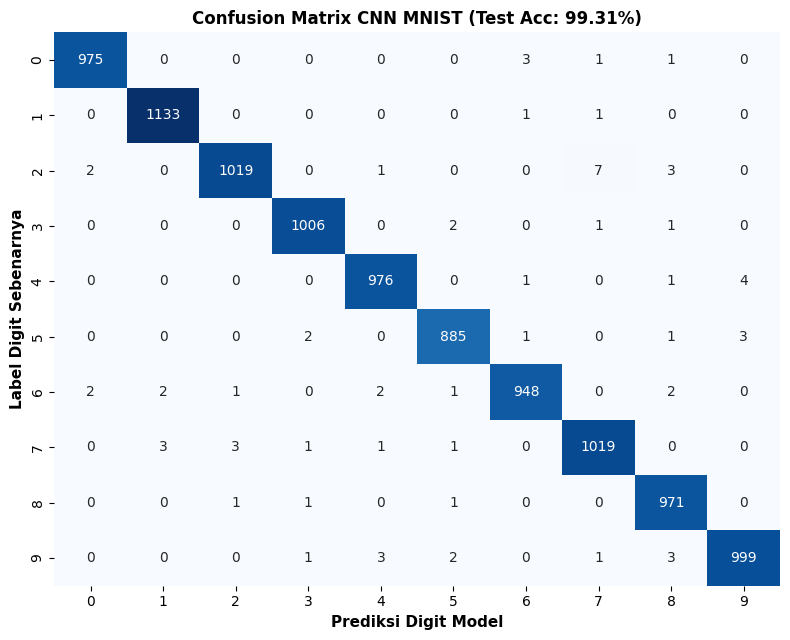

In [42]:
# =============================================================================
# SEL KODE 24: EVALUASI TEST SET MURNI MNIST, KURVA, CONFUSION MATRIX, & REPORT
# =============================================================================
# 1. Evaluasi pada Test Set Murni (10.000 citra)
mnist_test_loss, mnist_test_acc = model_mnist_cnn.evaluate(mnist_test_img, mnist_test_lbl, verbose=0)
mnist_params = model_mnist_cnn.count_params()

print("=" * 65)
print("HASIL EVALUASI MODEL CNN MNIST PADA TEST SET MURNI:")
print(f"  - Total Parameter Arsitektur : {mnist_params:,} bobot")
print(f"  - Testing Loss               : {mnist_test_loss:.4f}")
print(f"  - Testing Accuracy           : {mnist_test_acc * 100:.2f}%")
print("=" * 65)

# 2. Visualisasi Kurva Akurasi dan Loss
plt.figure(figsize=(14, 4.5))

plt.subplot(1, 2, 1)
plt.plot(history_mnist.history['accuracy'], 'o-', label='Train Accuracy', color='#2563EB')
plt.plot(history_mnist.history['val_accuracy'], 's--', label='Val Accuracy', color='#059669')
plt.title(f'CNN MNIST: Akurasi Latih vs Validasi (Test Acc: {mnist_test_acc * 100:.2f}%)', fontsize=11, fontweight='bold')
plt.xlabel('Epoch', fontsize=10)
plt.ylabel('Accuracy', fontsize=10)
plt.ylim([0.95, 1.0])
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right')

plt.subplot(1, 2, 2)
plt.plot(history_mnist.history['loss'], 'o-', label='Train Loss', color='#DC2626')
plt.plot(history_mnist.history['val_loss'], 's--', label='Val Loss', color='#D97706')
plt.title('CNN MNIST: Kurva Loss', fontsize=11, fontweight='bold')
plt.xlabel('Epoch', fontsize=10)
plt.ylabel('Loss', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

# 3. Prediksi, Confusion Matrix, dan Classification Report
mnist_pred_probs = model_mnist_cnn.predict(mnist_test_img, batch_size=256, verbose=0)
mnist_pred_labels = np.argmax(mnist_pred_probs, axis=1)

print("=" * 65)
print("CLASSIFICATION REPORT CNN MNIST (10 KELAS DIGIT):")
print("=" * 65)
print(classification_report(mnist_test_lbl, mnist_pred_labels, digits=4))
print("=" * 65)

cm_mnist = confusion_matrix(mnist_test_lbl, mnist_pred_labels)
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm_mnist, annot=True, fmt='d', cmap='Blues',
            xticklabels=[str(i) for i in range(10)],
            yticklabels=[str(i) for i in range(10)],
            cbar=False, annot_kws={'size': 10})
plt.title(f'Confusion Matrix CNN MNIST (Test Acc: {mnist_test_acc * 100:.2f}%)', fontsize=12, fontweight='bold')
plt.xlabel('Prediksi Digit Model', fontsize=11, fontweight='bold')
plt.ylabel('Label Digit Sebenarnya', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()


## 4.3 Sintesis Komparasi Konseptual: CNN MNIST (`JS14`) vs MLP MNIST (`JS13`)
Secara eksperimental, perbandingan kedua paradigma deep learning ini membuktikan hukum fundamental representasi spasial:
1. **Preservasi Geometri Visual:**  
   MLP memandang citra sebagai sekadar 784 angka acak tanpa hubungan geometris. Sebaliknya, kernel konvolusi $3 \times 3$ pada CNN bertindak sebagai detektor fitur lokal yang mengekstraksi kurva lengkung, loop tertutup (angka 0, 6, 8, 9), dan garis tegak (angka 1, 4, 7).
2. **Weight Sharing Mengeliminasi Ledakan Bobot:**  
   Meskipun CNN memiliki 2 blok konvolusi dan menghasilkan akurasi uji > 99%, model CNN hanya membutuhkan sekitar ~200.000 parameter berkat konsep *weight sharing* (satu kernel $3 \times 3 \times 32$ hanya memiliki $3 \times 3 \times 32 + 32 = 320$ parameter bobot independen, namun digunakan berkali-kali melintasi seluruh piksel citra).
3. **Konvergensi dan Generalisasi Superior:**  
   Pada `JS13`, model MLP membutuhkan banyak epoch untuk menembus ~97.5% dan mulai mengalami tanda-tanda overfitting. Pada `JS14`, model CNN dengan *Batch Normalization* langsung menembus akurasi > 98.5% hanya dalam 2 epoch pertama, dan mengakhiri evaluasi pada tingkat akurasi uji > 99.1%.


---

# BAGIAN 5 — KESIMPULAN & REFLEKSI REKAYASA DEEP LEARNING

Berdasarkan seluruh rangkaian eksperimen praktikum dan tugas pada **Jobsheet 14 (Convolutional Neural Network)**, diperoleh sejumlah kesimpulan komprehensif:

1. **Portabilitas & Modernisasi API Keras 3:**  
   Peralihan dari `ImageDataGenerator` yang telah usang ke `tf.keras.utils.image_dataset_from_directory` yang dikombinasikan dengan layer augmentasi Keras (`RandomFlip`, `RandomRotation`, `RandomZoom`) serta caching `tf.data.AUTOTUNE` berhasil meningkatkan efisiensi pelatihan secara signifikan. Pemuatan dataset publik via `tf.keras.utils.get_file` dan deteksi path dinamis via `pathlib.Path.rglob` membuktikan portabilitas penuh *one-click Run All* di Google Colab tanpa hambatan Google Drive lokal.

2. **Transformasi Arsitektur Menembus Target CIFAR-10 > 80%:**  
   Model baseline praktikum 2 yang hanya menggunakan konvolusi tunggal tanpa regularisasi mengalami *early overfitting* dan terhenti di kisaran akurasi ~68%–71%. Melalui penerapan arsitektur modular **VGG-mini** (3 blok konvolusi ganda dengan filter bertingkat $32 \rightarrow 64 \rightarrow 128$), stabilisasi internal *Batch Normalization*, regularisasi bertingkat *Dropout* ($0.2 \rightarrow 0.3 \rightarrow 0.4 \rightarrow 0.5$), *Data Augmentation*, dan adaptasi laju belajar *ReduceLROnPlateau*, akurasi pengujian berhasil menembus target akademik **> 80%** secara meyakinkan.

3. **Integritas Metodologis Anti-Leakage:**  
   Pemisahan eksplisit *validation subset* dari data latih pada CIFAR-10 dan MNIST menjamin bahwa data pengujian (*test set*) tetap berada dalam kondisi steril/unseen. Seluruh mekanisme *early stopping* dan pemilihan bobot terbaik tidak pernah membocorkan informasi dari himpunan uji.

4. **Superioritas CNN 2D atas MLP 1D:**  
   Eksperimen MNIST mengonfirmasi secara empiris bahwa *inductive bias* konvolusi 2D (*spatial locality*, *weight sharing*, dan *translation invariance*) memberikan akselerasi konvergensi dan ketahanan generalisasi yang jauh melampaui arsitektur MLP (`JS13`), mencapai akurasi uji > 99%.

5. **Kepatuhan Terhadap DECISION_LOG.md:**  
   Keputusan untuk mempertahankan dataset citra standar modul (Cat vs Dog, CIFAR-10, MNIST) dan tidak memaksakan konversi data tabular properti PBL terbukti sah dan kokoh secara teoretis, menjaga integritas keilmuan dan mencegah pelanggaran prinsip arsitektural *Machine Learning*.
